# Predicting pinches from EEG - VIBE experiment

**Goal.** In a VR selection task, participants looked at a stimulus and *pinched*
to select it. We ask three questions from the WearableSensing DSI‑24 EEG (300 Hz),
with Vive Pro Eye gaze (120 Hz nominal) as an optional aid:

1. **What is in the EEG?** - exploratory analysis of signal quality and the
   neural/ocular dynamics around a pinch.
2. **Can we *detect* a pinch?** - a classifier over causal EEG windows, swept over
   window size, evaluated cross‑subject and within‑subject, **with and without gaze**.
3. **Can we *predict a pinch before it happens*?** - a regressor for time‑to‑next‑pinch.

A dedicated section studies the real‑world **false‑positive problem** using
*distractor* stimuli the participant looked at but must not pinch.

*Code lives in `pinch_analysis/`; numeric results in `out/*.csv`; figures in
`out/figs/`. This notebook presents precomputed results by default.*

## 0 · Setup

In [105]:
# Auto-reload the pinch_analysis package so this notebook always executes the
# *latest* script source: edit any pinch_analysis/*.py, re-run a cell, and the
# change takes effect without restarting the kernel.
%load_ext autoreload
%autoreload 2

from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown
from pinch_analysis import pipeline   # one entry point to run any/all scripts

ROOT = Path.cwd()
if ROOT.name != "DataAnalysis" and (ROOT / "DataAnalysis").exists():
    ROOT = ROOT / "DataAnalysis"
OUT, FIGS = ROOT / "out", ROOT / "out" / "figs"

def show_fig(name, width=980):
    display(Image(filename=str(FIGS / name), width=width))
def show_csv(name):
    return pd.read_csv(OUT / name)

pd.set_option("display.float_format", lambda v: f"{v:.3f}")
print("analysis stages:", pipeline.ORDER)
print("outputs in", OUT)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
analysis stages: ['eda', 'classify', 'regress', 'hardneg', 'eegnet', 'transfer', 'baselines']
outputs in /home/nicolas/github/VIBE/DataAnalysis/out


### 0b · Reproduce from raw data (optional)

Every result below is loaded from `out/` (precomputed), so the notebook opens
fast. To regenerate from the raw recordings, run the cells in this section: each
calls a script's `main()` through `pipeline.run(...)`, which **reloads that script
from disk first**, so you always execute the current source. These cells are tagged
`skip-execution`, so re-running/executing the whole notebook does **not** trigger
the ~70-minute recompute - run them manually when you want to reproduce.

`pipeline.run_all()` uses a dependency-safe order (`baselines` last, as it reads
the classifier/EEGNet CSVs).

In [106]:
# Run EVERYTHING from the raw recordings (~70 min); regenerates all out/ CSVs+figs.
# pipeline.run_all()

In [107]:
# …or run individual stages on demand (edit the script, re-run - latest source):
pipeline.run("eda")         # signal quality, spectra, motor ERD, gaze  (~1 min)
# pipeline.run("classify")    # pinch detection + window sweep            (~4 min)
# pipeline.run("regress")     # time-to-next-pinch regressor              (~4 min)
# pipeline.run("hardneg")     # distractor hard-negative analysis         (~6 min)
# pipeline.run("eegnet")      # per-subject EEGNet vs distractors         (~25 min)
# pipeline.run("transfer")    # cross-subject transfer EEGNet             (~20 min)
# pipeline.run("baselines")   # constant-classifier comparison (run last) (~6 min)

=== running 'eda'  (run_eda.main) ===
== Inventory ==
     subject            stamp  eeg_dur_s   n_eeg  fs_eff  n_pinch  n_select  n_myo  exp_FourPositions  exp_FourPositionsGaze  exp_MyoFourPositions  exp_MyoTwoPositions  exp_RandomLarge  exp_RandomSmall  exp_Static  exp_Tutorial  exp_TwoPositions  exp_End
0  subject_5  20260609_143958   1831.300  549391 300.000      236       202      0                NaN                    NaN                   NaN                  NaN              NaN              NaN         NaN           NaN               NaN      NaN
1  subject_5  20260612_095751   1662.600  498768 300.000      256       230     49             20.000                 11.000                25.000               24.000           45.000           42.000      43.000         4.000            42.000      NaN
2  subject_6  20260610_110832   1832.800  549830 300.000      181       167      7             21.000                  8.000                   NaN                7.000           43.

## 1 · Data, alignment, and what counts as a pinch

Three streams share **one LSL clock** (the `timestamp` column, seconds), so
everything aligns by timestamp. Crucially, the EEG **`TRG` trigger channel is
all‑zero** - event locations come *only* from the marker timestamps, mapped to the
nearest EEG sample (robust to the small clock jitter).

**Pinch definition.** The task marks a pinch as `action=select,trial=N,
target=Stimuli(Clone)`. A `PinchLog` gesture fires ~19 ms earlier and is the
cleaner motor onset, so we use PinchLog onsets, annotated with the matching
select's trial/rt.

**Conditions:** `Static`, `TwoPositions`/`FourPositions`, `RandomSmall`/`RandomLarge`,
and the muscle‑activation `MyoTwoPositions`/`MyoFourPositions` (fingers still).

Data caveats handled by the loader: subject‑5 session 1 has no `ExperimentName`
(older build); subject‑6 has a 132 s false start and a 0‑byte gaze file; `Fz` is
flat and `O1/O2/T5/F4` saturate; `X1–X3` are flat aux (not EMG - the Myo pinches
came from a separate armband, the `MyoPinch` stream).

In [108]:
from pinch_analysis.run_eda import inventory
inv = inventory()
inv[["subject","stamp","eeg_dur_s","fs_eff","n_pinch","n_select","n_myo"]]

,subject,stamp,eeg_dur_s,fs_eff,n_pinch,n_select,n_myo
0,subject_5,20260609_143958,1831.300,300.000,236,202,0
1,subject_5,20260612_095751,1662.600,300.000,256,230,49
2,subject_6,20260610_110832,1832.800,300.000,181,167,7
3,subject_7,20260610_135312,1672.100,300.000,254,202,45
4,subject_8,20260611_094141,1777.700,300.000,269,189,3
5,subject_9,20260611_113240,1750.900,300.000,260,228,43


## 2 · Signal quality & spectra

Left: raw per‑channel amplitude for subject 8 - flat/saturating channels
(orange) are auto‑detected and interpolated. Right: 6 s of cleaned motor
channels. Preprocessing: 18 recorded scalp electrodes, 1–40 Hz band‑pass + 50 Hz
notch, **linked‑mastoid reference**, bad‑channel interpolation.

*Recording reference = Pz* (hence absent from the file). No correction needed:
linked‑mastoid re‑referencing cancels the online reference, so the recorded
channels are identical with or without reconstituting Pz (verified in
`validate_pz_reference.py`); `preprocess(restore_reference=True)` can optionally
recover Pz as a 19th electrode.

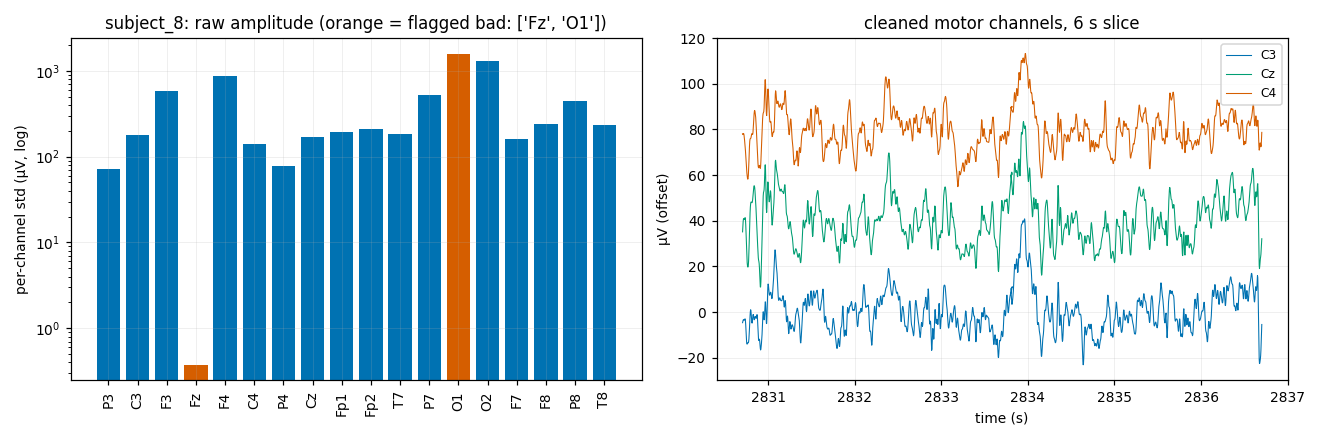

In [109]:
show_fig('01_signal_quality.png')

Cleaned scalp spectrum - 1/f with an ~8–10 Hz alpha bump is to be expected (Donoghue et al. (2020), "Parameterizing neural power spectra into periodic and aperiodic components); the notch removes mains (no 50 Hz peak).
The PSD (power spectral density) is computed per-session, here we see the mean of these PSDs, and the STD over all sessions in shaded blue (non-symmetrical as the y axis is logarithmic).

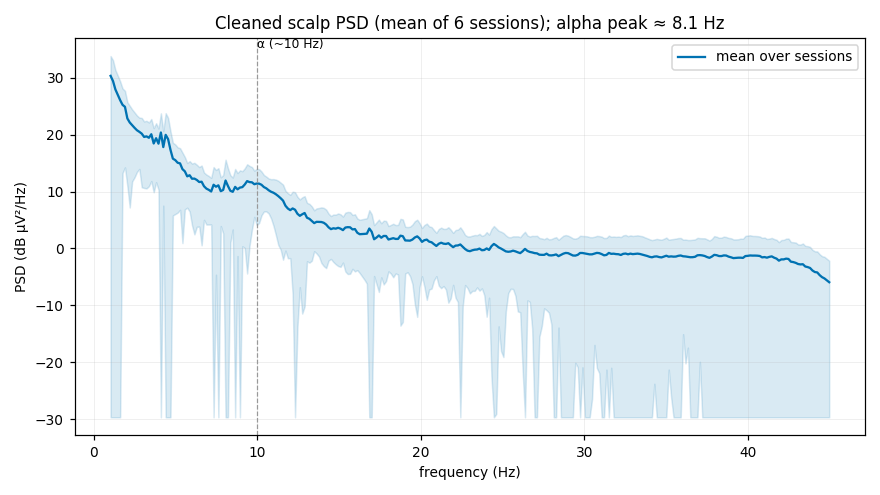

In [110]:
show_fig('02_psd.png')

## 3 · What the EEG detects - motor signature & gaze

**The key physiological result.** Locked to pinch onset (N$\approx$1200 pooled epochs):
a movement‑related potential, and a **mu/beta event‑related desynchronisation
(ERD)** that begins **~500 ms before** the pinch and is strongest at **C3**
(left/contralateral to the right hand). This is the textbook motor‑cortex
signature and the basis for decoding.

The ERD is expected and explained in [Event-related EEG/MEG synchronization and desynchronization: basic
principles, G. Pfurtschellera, F.H. Lopes da Silva](https://doc.ml.tu-berlin.de/bbci/teaching/PfuSil99.pdf).

The log-ratio is used as a scale to better compare different frequencies on the same color scale (for reference: $\pm .3 = $ half/double power. The visible $-0.15 \approx -30\%$).

The mu (8-12Hz) and Beta (13-30Hz) frequencies idle at high amplitude when the motor cortex is "at rest", and both desynchronize (drop in power) when a movement is planned or executed - the event related desynchronisation.

### The log-ratio

The log-ratio is a standard way of expressing time-frequency power relative to a baseline, computed via MNE's apply_baseline(..., mode="logratio") calls throughout run_eda.py (e.g. _epochs_tfr_logratio,
  _epochs_tfr_avg_logratio).

log_ratio(t) = log10( power(t) / mean(power_baseline) )

- power(t): the Morlet-wavelet power (squared amplitude) at a given frequency and time point.
- power_baseline: the mean power in a fixed reference window, here BASELINE = (-2.0, -1.5) s relative to the pinch (the first 0.5 s of the epoch, comfortably before any movement-related activity).

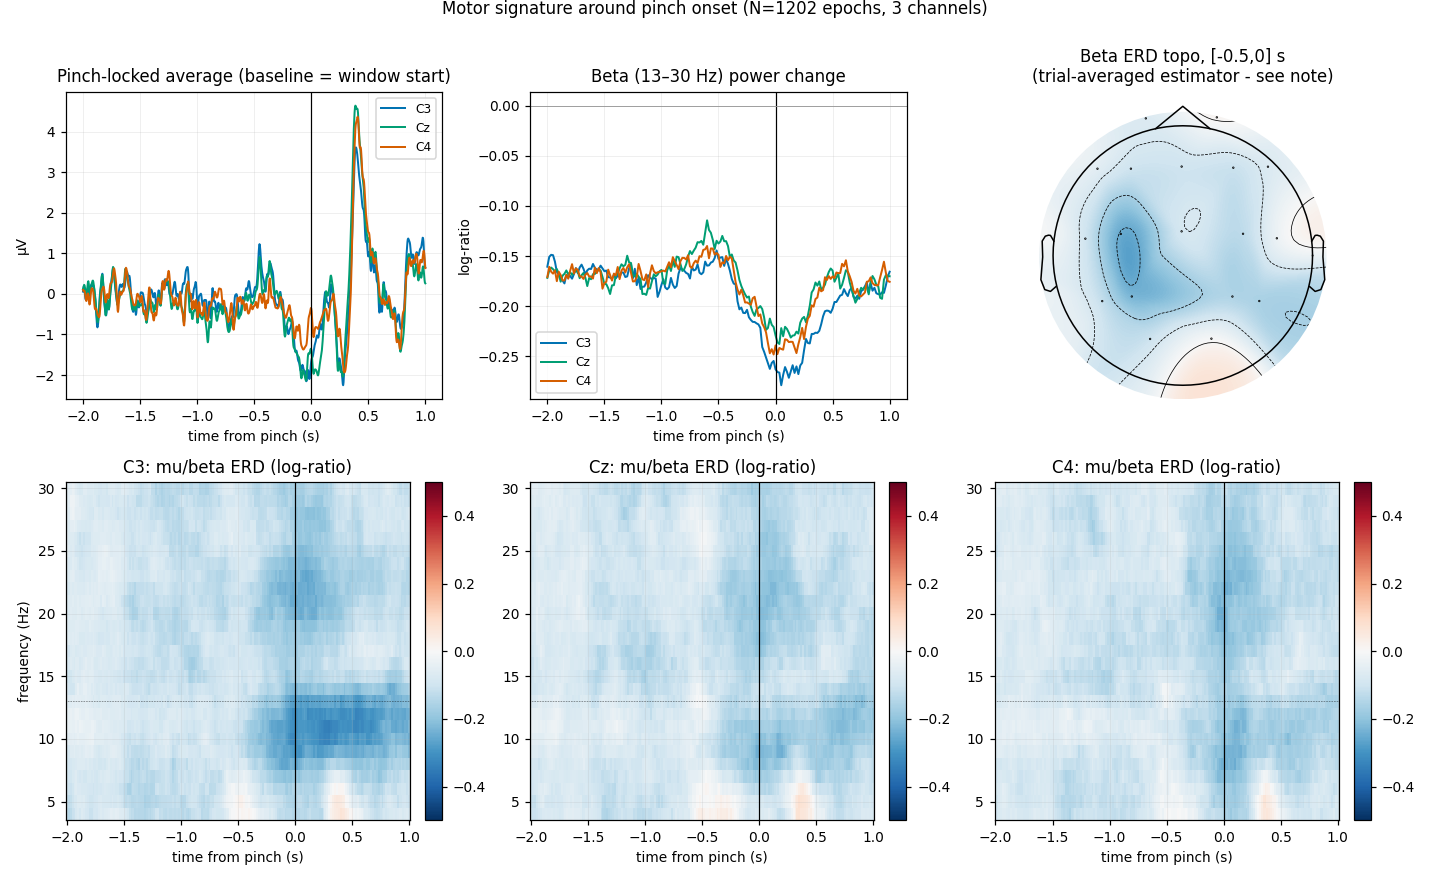

In [111]:
show_fig('03_pinch_motor.png')

**Methodology note - one normalization throughout.** Every beta/mu-ERD number
below (here and in §3b-3f) baseline-corrects **each epoch's power against its
own pre-movement window** (a single-trial log-ratio), then aggregates (median,
IQR where a distribution is shown) across whichever group of epochs is being
compared. One exception:
**the topomap** is a *cross-channel* comparison, and the single-trial bias is
essentially uniform across channels - it doesn't cancel there the way it does
across subjects/conditions, and empirically it collapses the real ~0.09
log-ratio C3-vs-occipital spread down to a washed-out ~0.03. So the topomaps
(here and in §3e) keep the trial-averaged estimator; every other panel uses
the single-trial one, and each topomap is captioned accordingly.

**Edge padding.** Epochs are built 0.5 s wider on each side than the
`[-2, 1] s` actually plotted. A Morlet wavelet needs signal on both sides
of every time point it estimates - without that margin, the convolution runs
out of data right at the display edges and the power estimate there is
artificially suppressed, showing up as a spurious sharp dip at the very
start/end of every log-ratio trace or heatmap. Every TFR here is computed on
the padded epoch and cropped back to the display window only *after* baseline
correction, so that edge artifact never reaches a figure.

**Violin Plot.** The Violin plot shows the average log-ratios of the window [-0.5,0]s of the electrodes C3 and C4 averaged together, separated by subject.

**How much does this vary?** The grand-average above pools all 1202 epochs
across 5 subjects (6 sessions). The
figures below decompose the same beta-band (13-30 Hz) ERD at C3+C4 by subject,
by run (for the subject recorded twice), and by experiment condition - each
as a **median ± IQR trace** and a **per-epoch distribution** (violin/box), so the
spread across single trials is visible, not just a mean.

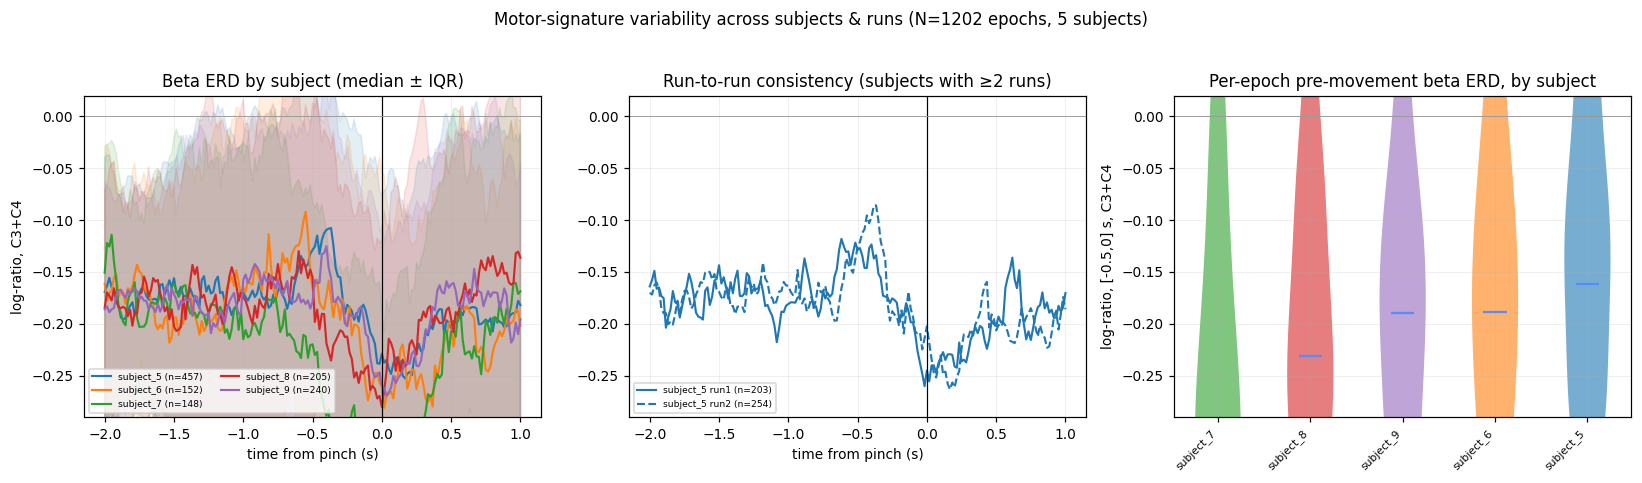

In [112]:
show_fig('03b_motor_by_subject.png')

**Read-out - subjects & runs.** Per-subject median pre-movement beta ERD ranges
from **-0.32** (subject_7, strongest) to **-0.16** (subject_5, weakest) log-ratio -
individual differences are large relative to the grand-average effect shown
above. Where a subject was recorded twice (subject_5, two full sessions), the
runs agree closely (medians -0.16 vs -0.16), so the between-subject spread
reflects real individual variation, not session drift.

**Does the condition matter?** Trials come from `Static`, `TwoPositions`/
`FourPositions` (± a gaze-cued variant), `RandomSmall`/`RandomLarge`, and the
muscle-activation `MyoTwoPositions`/`MyoFourPositions` conditions - in the Myo
conditions the fingers stay still and the "pinch" is a muscle co-contraction
picked up by a separate armband. If the ERD above were mostly a movement/EMG
artifact of the visible finger motion rather than a genuine motor-cortex signal,
the Myo trials (no finger movement) should show a much weaker effect.

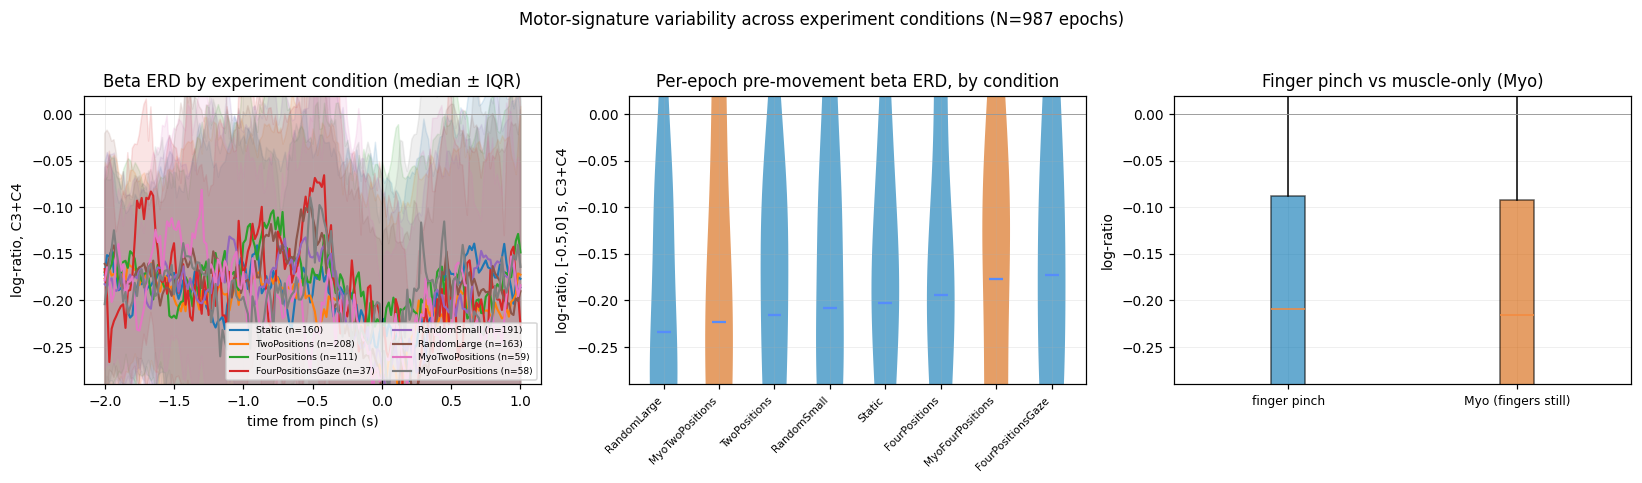

In [113]:
show_fig('03c_motor_by_experiment.png')

**Read-out - experiment condition.** Per-condition median ERD ranges from **-0.23**
(`RandomLarge`) to **-0.17** (`FourPositionsGaze`), and finger-pinch conditions
pooled (**-0.21**) are virtually indistinguishable from the Myo conditions pooled
(**-0.22**). The desynchronisation is **not weaker when the fingers stay still** -
consistent with the effect being a genuine motor-cortex/motor-planning signature
rather than an artifact of the visible pinch movement, and reassuring for the
Myo-armband ground truth used elsewhere in this notebook.

### 3e · Single-subject case study - subject_7

subject_7 has the strongest grand-average beta ERD of the cohort (§3b). Two
more targeted views ask questions the group-level plots above can't: (1) is
the dip at t0 visible in individual trials, or only after averaging away the
noise? (2) does the C3-focused spatial pattern from §3's topomap hold in
*every* experiment condition for this subject, or is it dragged by one or two
of them?

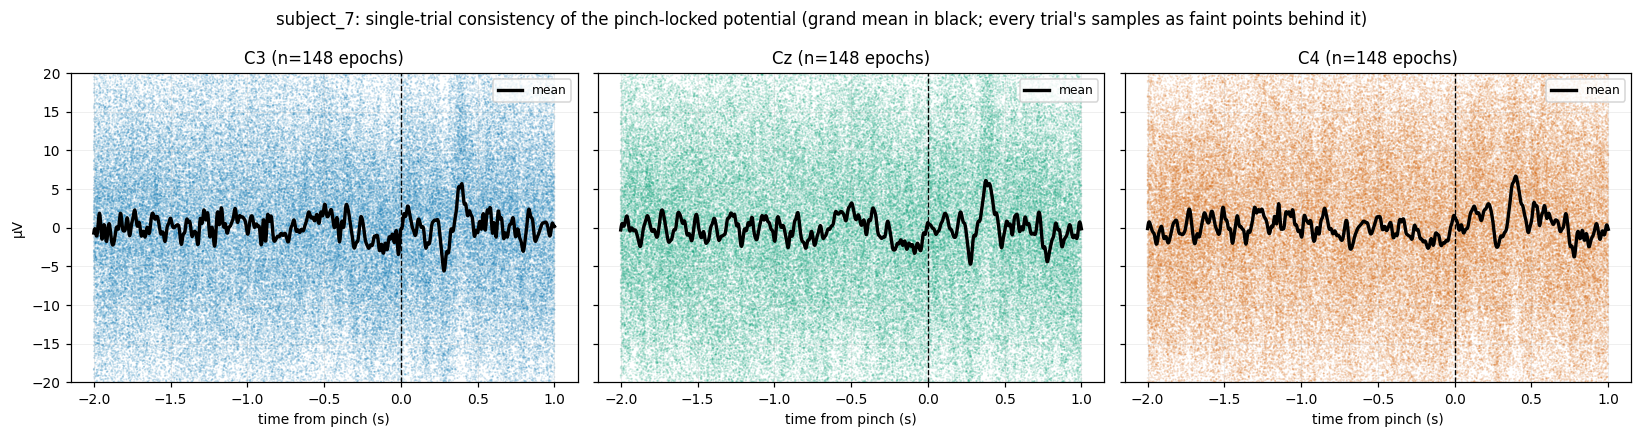

In [114]:
show_fig('03e_subject_erp_spaghetti.png')

**Read-out.** Each faint point is one sample from one trial (y-axis clipped to
±20 µV so the point cloud isn't dominated by a handful of large-amplitude
trials); the black line is the grand mean. The cloud shows what single-trial
EEG actually looks like - ordinary background oscillation, tens of µV wide,
against a ~1-2 µV deterministic dip, so no individual trial is readable by eye.
But that dip is not just an averaging artifact: at C3, the mean amplitude in
the [-0.3, +0.1] s window is negative on **61%** of subject_7's 148 individual
trials (median -0.86 µV vs. baseline; Wilcoxon signed-rank against 0,
**p=0.0082**) - a modest but statistically real trial-by-trial majority,
exactly what you'd expect from a small deterministic signal riding on large
single-trial noise.

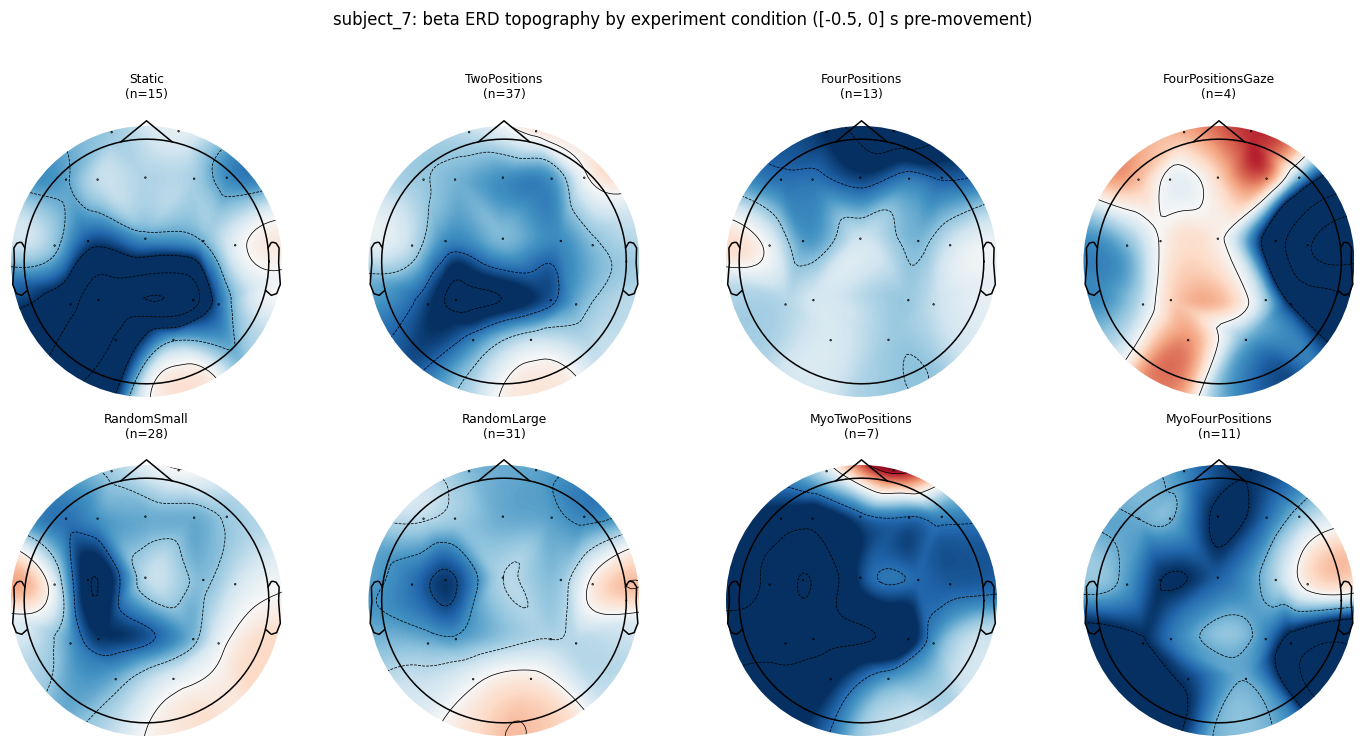

In [115]:
show_fig('03f_subject_topo_by_experiment.png')

**Read-out.** The left-lateralized (C3-side) desynchronisation shows up
condition-by-condition too, not just in the pooled §3 topomap - clearest in the
higher-trial-count conditions (`Static` n=15, `TwoPositions` n=37, `RandomSmall`
n=28, `RandomLarge` n=31). `FourPositionsGaze` is left blank here (n<5, too few
trial-averaged epochs to trust); `MyoTwoPositions` (n=7) and `MyoFourPositions`
(n=11) are visibly noisier but still mostly left-lateralized, including the
muscle-only Myo conditions - a reminder to read per-condition topomaps with n in
mind, especially at the per-subject level.

**Gaze is strongly pinch‑locked.** Angular speed collapses to a fixation minimum
*exactly at the pinch* (saccade into the target ~500 ms before; saccade away
after). Pupil peaks ~400 ms pre‑pinch; eye openness dips just after (a
post‑selection blink). Angular speed might be used as a helping indicator for when to expect pinches.

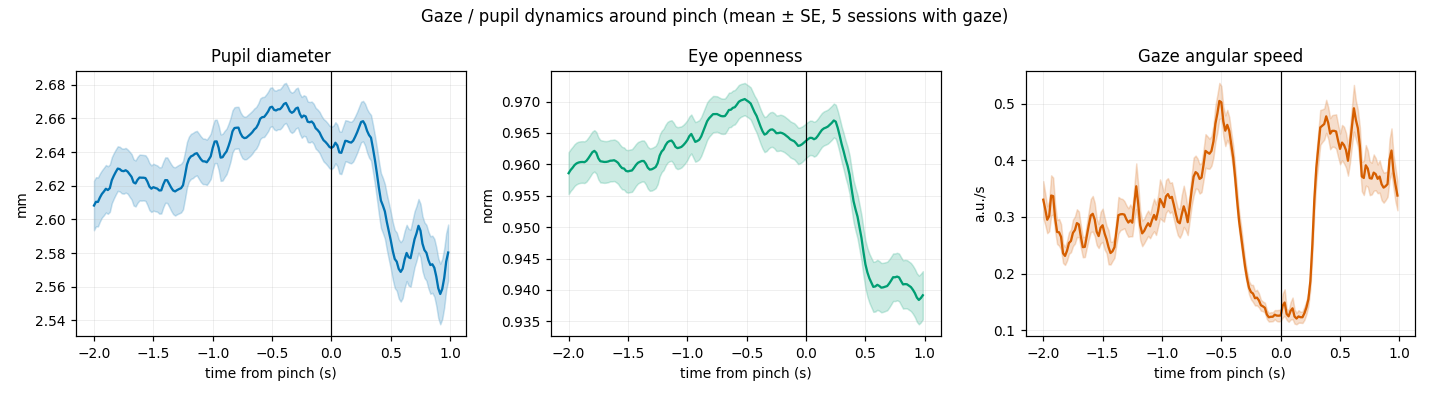

In [116]:
show_fig('04_gaze.png')

## 4 · Pinch detection (classifier)

**Framing (causal, online‑decodable).** A window ends at the reference time `t0`:
*positive* `[t0−W, t0]` with a pinch at `t0`; *negative* `[t−W, t]` with `t` ≥
`W+1 s` from every pinch. Window `W ∈ {0.5, 1, 1.5, 2}` s, negatives ≈ 2:1.

**Feature sets** - note the two **EEG‑only** variants (the requested gaze‑free run):
`riemann` (tangent space of 8–30 Hz covariances), `bandpow` (band power + Hjorth),
and `bandpow+gaze`.

**Two evaluations:** leave‑one‑subject‑out (**cross‑subject**, generalising to a
new person) and within‑subject temporal 5‑fold (**calibrated‑BCI ceiling**).

In [117]:
cls = show_csv("classify_results.csv")
disp = cls.pivot_table(index="window_s", columns="feature_set",
                       values=["auc","within_auc_mean"])
disp

auc                      within_auc_mean                     
feature_set bandpow bandpow+gaze riemann         bandpow bandpow+gaze riemann
window_s                                                                     
0.500         0.626        0.632   0.657           0.681        0.722   0.708
1.000         0.626        0.644   0.620           0.711        0.744   0.652
1.500         0.633        0.670   0.598           0.710        0.740   0.656
2.000         0.611        0.657   0.566           0.704        0.737   0.662

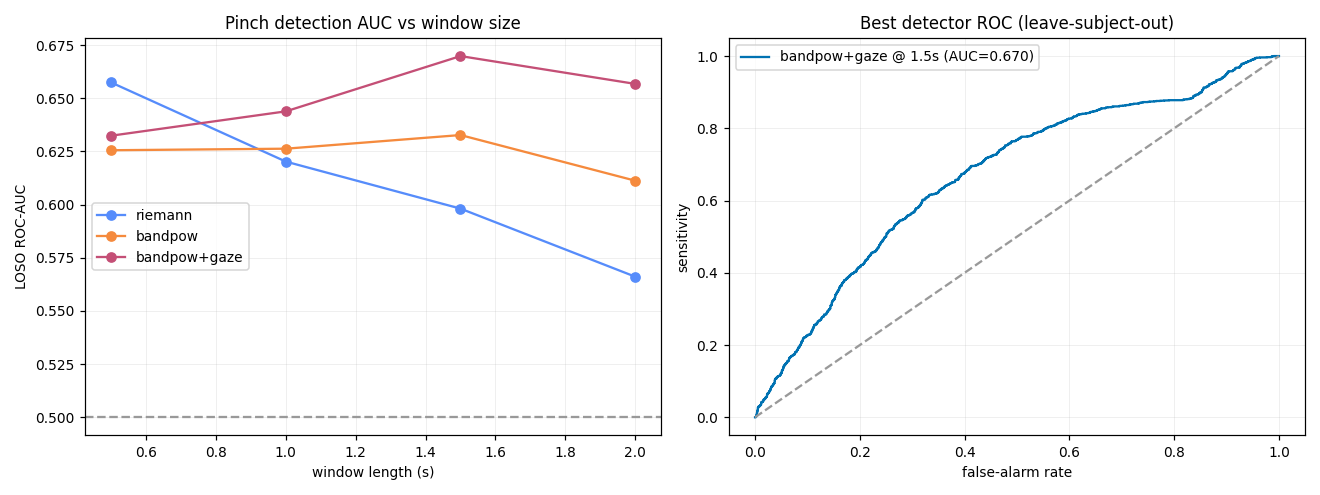

In [118]:
show_fig('06_classify.png')

**Read‑out.**
- A pinch **is** decodable: cross‑subject AUC ≈ **0.67**, within‑subject ≈ **0.74**
  (band power + gaze). **EEG‑only** reaches 0.63 (cross) / 0.71 (within).
- **Gaze adds +0.03–0.05 AUC** everywhere.
- **Window × feature interaction:** the Riemannian detector peaks at the short
  **0.5 s** window (instantaneous ERD); band‑power+gaze prefers 1–1.5 s (long
  enough to see the saccade→fixation pattern).

But these negatives are *easy* - windows far from any stimulus. §5 asks the harder,
real‑world question.

## 4b · Sanity check - comparison to a constant classifier

Is the classifier doing anything, or riding class imbalance? A **constant
(majority-class) classifier** always predicts "no pinch". On this data
(prevalence 0.36) it is the honesty check: we compare it, and a stratified-random
dummy, to the real models on a **full metric suite** (leave-one-subject-out, W=1 s).

In [119]:
bl = show_csv("baseline_results.csv")
bl.set_index("model")

,accuracy,balanced_acc,f1,roc_auc,pr_auc
model,,,,,
constant (majority),0.636,0.500,0.000,0.466,0.348
stratified random,0.532,0.494,0.355,0.494,0.361
eeg-bandpow,0.612,0.592,0.494,0.626,0.449
eeg-riemann,0.600,0.580,0.480,0.620,0.458
bandpow+gaze,0.626,0.604,0.505,0.644,0.472


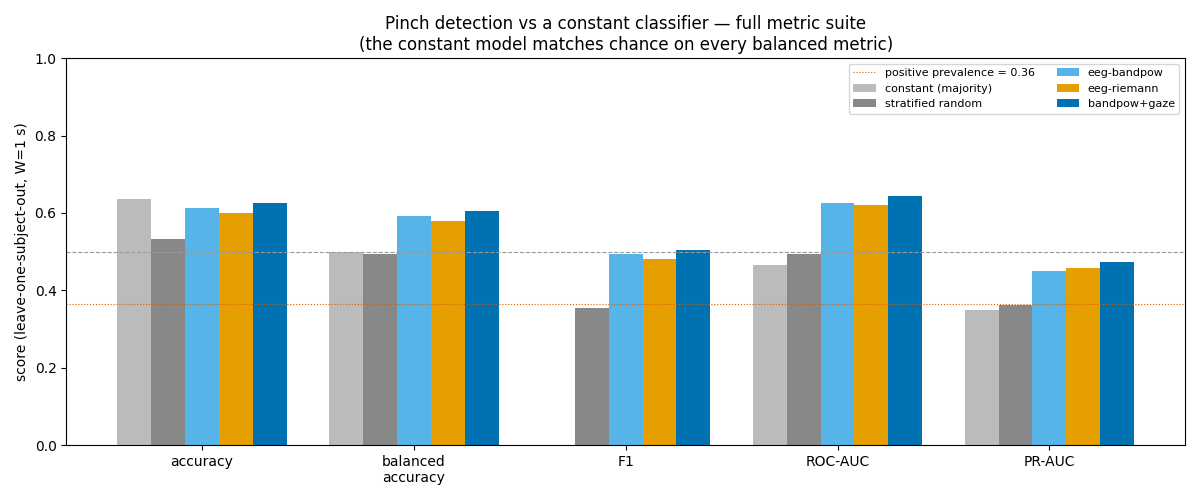

In [120]:
show_fig('11_baselines.png')

**The imbalance trap, made explicit.** The **constant classifier gets the *highest*
raw accuracy (0.64) beating every real model**. The real models trail it on raw accuracy yet beat
it decisively on every metric that is not fooled by imbalance (balanced accuracy
0.58–0.60, F1 0.48–0.51, ROC-AUC 0.62–0.64, PR-AUC 0.45–0.47).

**Every generated model vs the constant baseline** (`baseline_summary_allmodels.csv`). A peri-onset window $[t-0.5, t+0.5]$ is used for the classifier input.

In [121]:
show_csv("baseline_summary_allmodels.csv").set_index("model")

,roc_auc,note_prevalence
model,,
"Detection LOSO (bandpow+gaze, best W)",0.670,0.364
"Detection within-subj (bandpow+gaze, best W)",0.744,0.364
Pinch vs distractor: EEGNet (per-subj),0.838,NaN
Pinch vs distractor: Riemann (per-subj),0.822,NaN
Transfer EEGNet (zero-shot),0.697,NaN
Transfer EEGNet (fine-tuned),0.825,NaN
Constant classifier (any task),0.500,NaN


The constant classifier sits at ROC-AUC 0.50 by construction; **all generated
models clear it** - from the cross-subject detector (0.67) up to the per-subject and
fine-tuned distractor decoders (0.82–0.84).

## 5 · The false‑positive problem - distractor hard negatives

In real use, a participant looks at **many** stimuli without pinching. Some
stimuli are explicitly **highlighted‑negative** (`IsHighlightedNegative=true`) -
"look, don't pinch". Their `GAZE_ENTER` events reproduce the *exact* gaze pattern
of a real target (saccade in + fixation) with **no motor pinch**. Placed one
fixation‑dwell (~0.35 s) after gaze‑enter, they become **hard negatives** whose
window ends at the same phase as a positive window ends at the pinch - so the only
thing distinguishing them from a pinch is the **motor EEG**.

We train each detector on positives + random + hard negatives, then score, per
fold, `pinch vs random` (easy) and `pinch vs hard` (honest). The input window is $[t-0.5, t]$ (compared to previous numbers a peri-onset window)

In [122]:
hn = show_csv("hardneg_results.csv")
hn[hn["window_s"]==0.5][["eval","feature_set","auc_vs_random","auc_vs_hard",
                         "fa_hard@90sens"]].reset_index(drop=True)

,eval,feature_set,auc_vs_random,auc_vs_hard,fa_hard@90sens
0,cross-subject,gaze,0.602,0.483,0.905
1,cross-subject,eeg-bandpow,0.615,0.450,0.940
2,cross-subject,eeg-riemann,0.645,0.506,0.914
3,cross-subject,eeg+gaze,0.647,0.466,0.935
4,within-subject,gaze,0.637,0.347,0.946
5,within-subject,eeg-bandpow,0.677,0.465,0.960
6,within-subject,eeg-riemann,0.702,0.518,0.917
7,within-subject,eeg+gaze,0.648,0.442,0.944


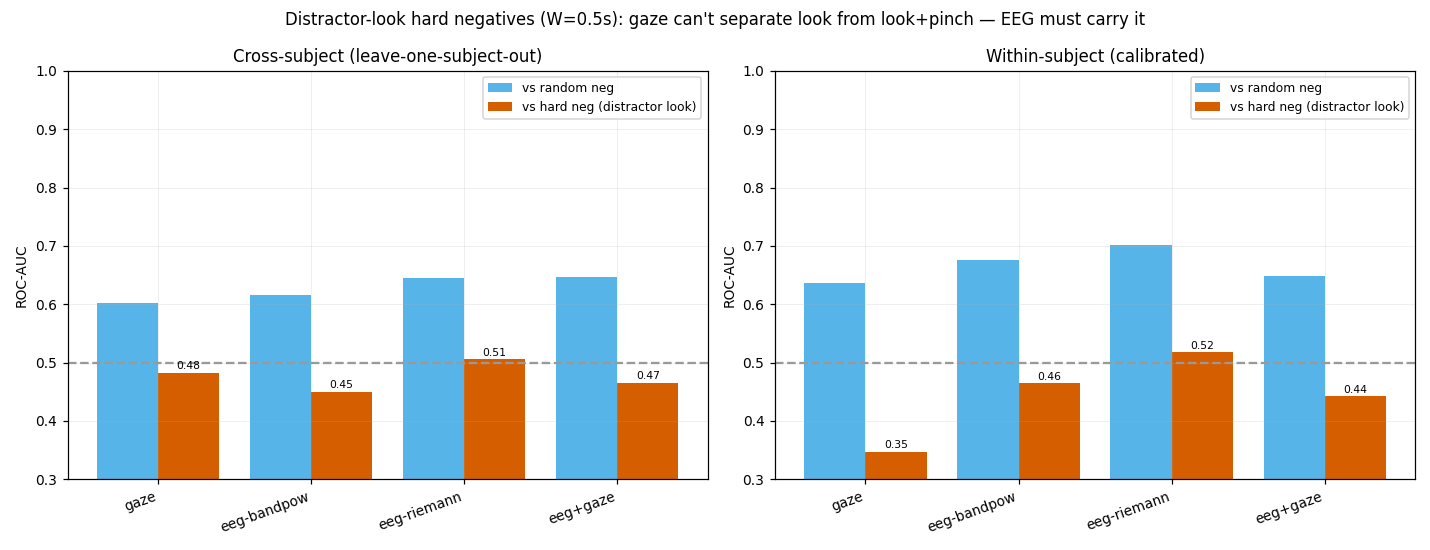

In [123]:
show_fig('08_hardneg.png')

**This is the important, sobering result.**
- Against **random** negatives every detector looks fine (AUC 0.6–0.7).
- Against **hard** distractor negatives, performance **collapses to chance** - and
  **gaze‑only falls *below* chance (AUC ≈ 0.34 within‑subject): it ranks a
  distractor look as *more* pinch‑like than an actual pinch.** At a 90 %‑sensitivity
  operating point, ~90 % of distractor looks would fire a false pinch.
- EEG‑only is marginally above chance (~0.52) but not usefully so at single‑trial,
  cross/within subject.

**Interpretation.** The strong `pinch‑vs‑random` EEG score was largely driven by
**non‑motor confounds** (visual attention, eye‑movement artifact) that vanish when
the negative is *also* a look at a stimulus. Isolating the true motor contribution,
it is real (the grand‑average ERD in §3) but too variable to separate look from
look+pinch at single‑trial with these features. **Takeaway:** a deployable pinch
detector cannot lean on "eyes‑on‑target"; it needs a genuinely motor‑specific EEG
decoder (per‑subject calibration, CSP/EEGNet, tighter pre‑movement windows), and
hard negatives are essential for honest evaluation.

**Is the pre-movement EEG itself indistinguishable, or is that just what the
classifier does with it?** The hard-negative test above is a classifier result;
here we ask the same question directly on the signal. We pool the real pinches
("hard positives" in the §5 sense) and the hard-negative distractor-look epochs
(same `[-2, 1] s` window around the reference onset, same C3+C4 beta-band ERD
computation as §3) and compare their **median ± IQR** ERD traces, their per-epoch
distributions, and the per-subject breakdown.

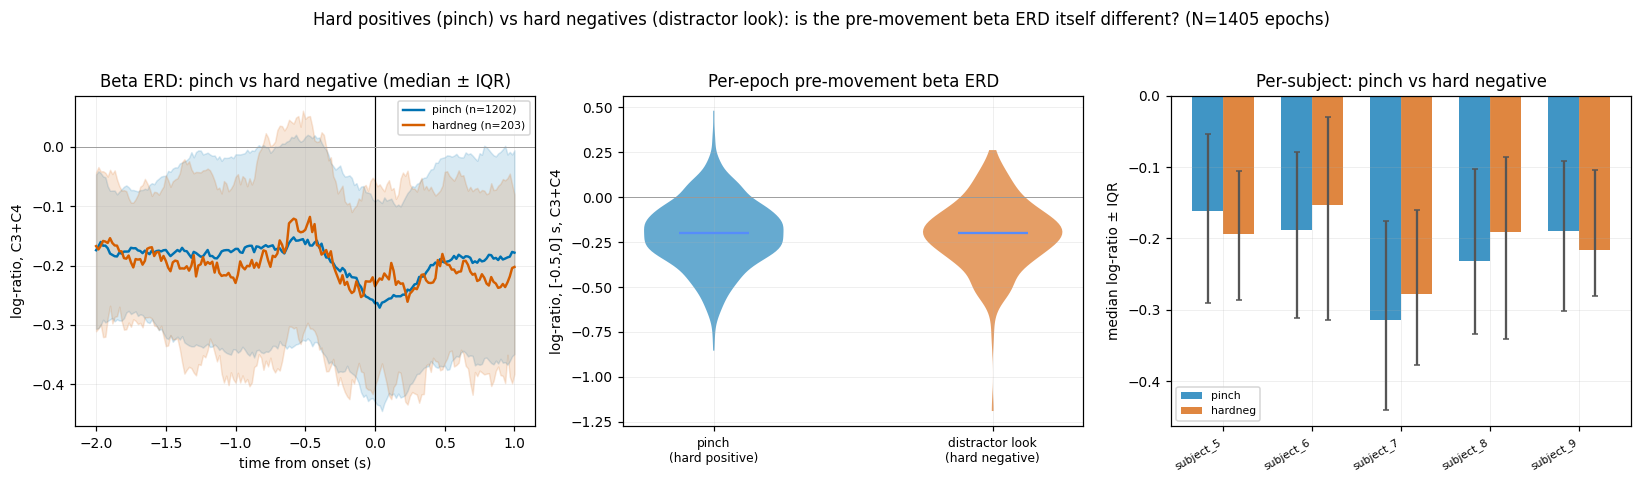

In [124]:
show_fig('03d_motor_pinch_vs_hardneg.png')

**Read-out.** Pinch and hard-negative traces sit almost on top of each other
throughout the whole `[-2, 1] s` window - median pre-movement beta ERD is
**-0.20** (pinch) vs **-0.20** (hard negative), not significantly different
(Mann-Whitney p=0.93, n=1202 vs 203), and the per-subject panel shows this holds
for every subject, not just on average. **This confirms §5's classifier result
at the signal level**: it isn't that the classifier fails to exploit a real
difference - on this feature (single-trial pre-movement beta-band power at
C3+C4), there essentially *is no difference* to exploit. Whatever separates a
real pinch from a distractor look must be sought elsewhere - the peri/post-onset
window used by the §5b/§5c EEGNet decoders, not the pre-movement ERD alone.

## 5b · A motor-specific decoder - EEGNet per subject

The §5 hard-negative test used a *causal pre-movement* window and found EEG could
barely separate a pinch from a distractor look. But the pre-movement signal is
weak; the *movement itself* is not. Here we train a compact **EEGNet per subject**
on a **peri-onset window `[-0.5, +0.5] s`** - i.e. a *verification* decoder that,
at the moment a pinch is registered, confirms it is a genuine motor act rather
than a distractor look (which gaze cannot do - the gaze pattern is identical).

Positives = real pinches; negatives = highlighted-negative distractor looks. Within
subject, stratified 5-fold, EEGNet ensembled over 3 seeds; a Riemannian
tangent-space model is trained on the identical folds as a baseline.

In [125]:
egn = show_csv("eegnet_results.csv"); egn

,subject,n_pos,n_hardneg,eegnet_auc,riemann_auc
0,subject_5,486,70,0.926,0.806
1,subject_6,170,37,0.886,0.874
2,subject_7,231,38,0.795,0.847
3,subject_8,254,46,0.839,0.797
4,subject_9,255,35,0.745,0.784


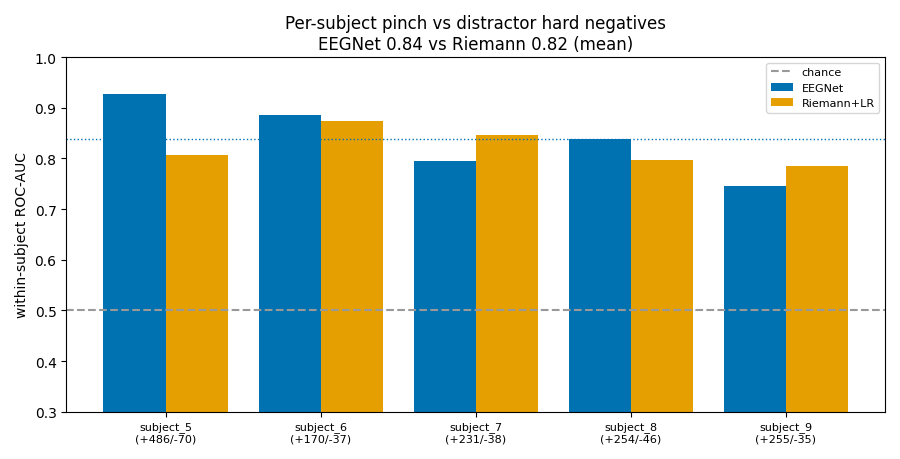

In [126]:
show_fig('09_eegnet.png')

**Read-out.** With a window that actually contains the movement, the motor EEG
**cleanly** separates a genuine pinch from a distractor look: **EEGNet averages
~0.84 AUC and the Riemannian baseline ~0.82** (every subject 0.75–0.93) - a large
jump over the ~0.52 of the causal *pre*-movement window in §5. EEGNet wins on the
subjects with the most data (subject 5: 0.93 with 486/70 epochs); the classical
Riemannian model stays competitive when per-subject data is smallest (≈35 negatives),
as expected for a lower-variance model. Both would gain from cross-subject
pretraining, but even per-subject from scratch they work.

**Design implication for a real system:** combine gaze with a motor-specific EEG decoder over a peri-onset window (not using a peri-onset window will not be able to distinguish positives from hard negatives).

## 5c · Cross-subject transfer - pretrain on others, calibrate per user

Two upgrades over §5b. First, a **richer negative set**: distractors now combine
**random inter-pinch windows** (task-block windows ≥ 2.5 s from any pinch) *and*
**highlighted-negative distractor looks** - more, and more varied, negatives.
Second, **transfer learning**: for each held-out subject we pretrain EEGNet on the
*other* subjects, then compare, on the same temporally-held-out test split:

* **scratch** - trained only on that subject's calibration half,
* **zero-shot** - the pretrained net applied with no calibration,
* **fine-tuned** - the pretrained net fine-tuned on the calibration half (run .learn() on 50% of the target's windows).

AUC is reported overall and split by negative type (`vs random`, `vs hard`).

In [127]:
tr = show_csv("eegnet_transfer_results.csv")
tr.groupby("condition")[["auc_all","auc_vs_hard","auc_vs_rand"]].mean() \
  .reindex(["scratch","zero-shot","fine-tuned"])

,auc_all,auc_vs_hard,auc_vs_rand
condition,,,
scratch,0.788,0.705,0.819
zero-shot,0.697,0.659,0.710
fine-tuned,0.825,0.759,0.846


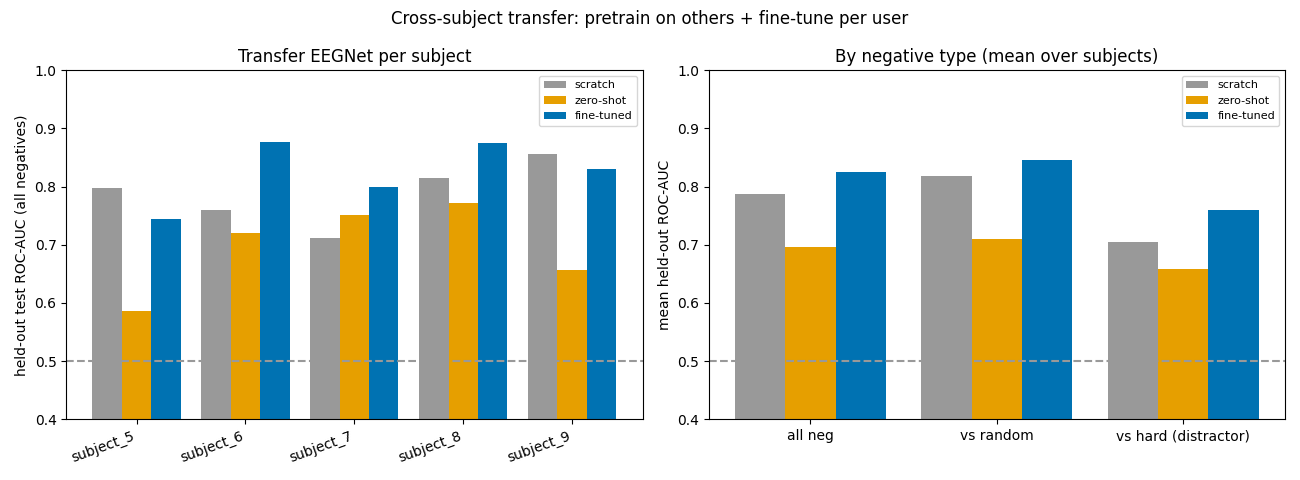

In [128]:
show_fig('10_eegnet_transfer.png')

**Read-out - transfer helps.**
- **Fine-tuned (pretrain + calibrate) is the best decoder**: mean **0.83 AUC**
  overall and **0.76 vs hard distractors**, beating **scratch** (0.79 / 0.71) - so
  pretraining across people and adding a little per-user calibration beats training
  from that same calibration data alone, and it helps most on the hard contrast.
- **Zero-shot** (a new user, *no* calibration) already clears chance (~0.70 overall,
  ~0.66 vs hard) - a pretrained model transfers partially out of the box.
- The one exception (subject 5, where scratch ≥ fine-tuned) is the subject with the
  most data and a different protocol build, where scratch is already saturated.

## 6 · Predicting future pinches (regressor)

Slide a 1 s causal window (0.25 s step) across the task blocks and regress
**time‑to‑next‑pinch** (capped at 2 s). Features are **EEG‑only**, gaze‑only, or
both; evaluation is leave‑one‑subject‑out; baseline = predict the mean.

In [129]:
reg = show_csv("regress_results.csv"); reg

,features,model,mae_s,r2,spearman,n,imminent_auc
0,eeg,ridge,0.453,-0.057,0.088,180221,0.545
1,eeg,hgb,0.449,-0.044,0.091,180221,0.548
2,eeg+gaze,ridge,0.445,-0.013,0.149,180221,0.579
3,eeg+gaze,hgb,0.444,-0.012,0.171,180221,0.588
4,gaze,ridge,0.451,0.021,0.171,180221,0.602
5,gaze,hgb,0.439,0.030,0.201,180221,0.621


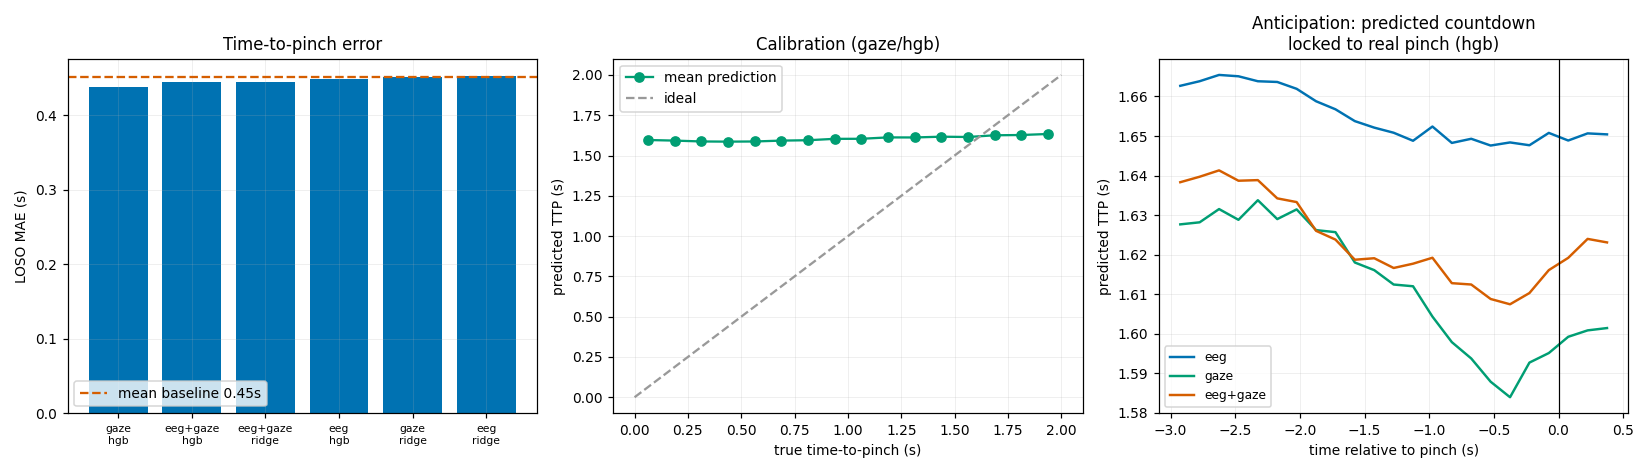

In [130]:
show_fig('07_regress.png')

- All models beat the mean baseline (MAE  s); the relationship is monotonic
  (Spearman ρ up to 0.28) though R² is small - most windows are "far from a pinch".
- The **anticipation is real and event‑locked** (right panel): the predicted
  countdown ramps down as a pinch approaches, bottoming **~0.5 s before onset**.
- **Gaze carries most of the predictive power** (the eyes fixate the target ~1 s
  before the hand acts); **EEG‑only** still beats baseline (ρ ≈ 0.17, imminent‑pinch
  AUC ≈ 0.56) - its premotor lead is only ~0.5 s.

## 7 · Conclusions

1. The EEG contains a **genuine motor signature** of the pinch (contralateral C3
   mu/beta ERD from ~0.5 s before onset).
2. **Detection works** - ~0.67 AUC cross‑subject, ~0.74 with per‑user calibration;
   EEG‑only is a few points lower. Riemannian covariances are the best pure‑EEG
   method and need only 0.5 s.
3. **Prediction** of a future pinch works but only ≲1 s ahead.
4. **Gaze is the stronger single modality but is a liability for detection**:
   against distractor looks it is worse than chance. A real system must fuse gaze
   with a *motor‑specific* EEG decoder, and must be validated on hard negatives.
5. **A peri‑onset EEG decoder (EEGNet / Riemann, §5b) verifies a genuine pinch vs
   a distractor look far above chance** (~0.84 per subject) - the practical way to
   suppress distractor false positives.
6. **Cross‑subject transfer works (§5c):** pretrain EEGNet on other users, fine‑tune
   per user → best decoder (~0.83 overall, ~0.76 vs distractors), beating scratch;
   zero‑shot (no calibration) already clears chance. Ship pretrained, calibrate briefly.
7. Practical caveats: dry‑electrode channels need interpolation; the unused `TRG`
   means timing rests on the LSL marker clock; single‑trial *pre‑movement*
   sensitivity is modest - the reliable signal is *peri/post‑movement*.